


+# Code-Cohesion Supply-Chain Detection — Clean Pipeline
**Part 1**: build the paired feature matrix · **Part 2**: feature validation + LR detector.

No project capping (per decision). gtk dominates pairs, so the split balances *projects* (not pairs) to keep CV runnable, and Step 5 will report per-project.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## Part 0 — Config & conventions

In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd
import json
import warnings
warnings.simplefilter('ignore')

DATA          = Path('/content/drive/MyDrive/Code Cohesion/new_method/data/')
# raw (broken/appended) files -> repaired files used everywhere downstream
CLEAN_CSV     = DATA / 'cohesion_metrics_clean.csv'
MALWARE_CSV   = DATA / 'cohesion_metrics_malware.csv'
OUT_MATRIX    = DATA / 'pairs_matrix.csv'
OUT_SPLIT     = DATA / 'project_split.json'

PROJECT_SEP = '|'      # func_id = project|file|funcname
SPLIT_SEED  = 42

RATIOS      = [100, 1000, 10000]

# Cohesion metrics used. and_penalty REMOVED. (b2n_hmean excluded: present on too few rows.)
METRICS_RAW = ['agreement','semantic','entropy_score',
               'n2b_mean','n2b_min','b2n_mean','b2n_min',
               'avg_chars','avg_tokens','multi_word_rate',
               'generic_rate','non_generic_rate','content_word_rate']
# True = higher means MORE cohesive; False = invert (1 - x)
HIGHER_IS_COHESIVE = {m: True for m in METRICS_RAW}
HIGHER_IS_COHESIVE['generic_rate'] = False     # more generic names = less cohesive

## Part 1 — Paired feature matrix
### 1.0 One-time CSV repair (column-shift from appended `b2n_hmean`)

### 1.1 Load, orient metrics (higher = more cohesive), clean keys

In [ ]:
def to_cohesion_oriented(df):
    df = df.copy(); coh = []
    for m in METRICS_RAW:
        col = 'c_' + ('and_consistency' if m == 'and_penalty' else m)
        df[col] = df[m] if HIGHER_IS_COHESIVE[m] else (1.0 - df[m])
        coh.append(col)
    return df, coh

clean   = pd.read_csv(CLEAN_CSV)
malware = pd.read_csv(MALWARE_CSV)
clean,   COH = to_cohesion_oriented(clean)
malware, _   = to_cohesion_oriented(malware)

n0c, n0m = len(clean), len(malware)
clean   = clean.dropna(subset=COH).drop_duplicates(['func_id','version'])
malware = malware.dropna(subset=COH).drop_duplicates(['func_id','version','injection_pos'])
print(f'clean:   {n0c:,} -> {len(clean):,}   malware: {n0m:,} -> {len(malware):,}')
print('oriented feature columns:', COH)

clean:   376,732 -> 312,287   malware: 409,262 -> 387,946
oriented feature columns: ['c_agreement', 'c_semantic', 'c_entropy_score', 'c_n2b_mean', 'c_n2b_min', 'c_b2n_mean', 'c_b2n_min', 'c_avg_chars', 'c_avg_tokens', 'c_multi_word_rate', 'c_generic_rate', 'c_non_generic_rate', 'c_content_word_rate']


In [ ]:
import os
print(f"Contents of {DATA}:")
for item in os.listdir(DATA):
    print(f"- {item}")

Contents of /content/drive/MyDrive/Code Cohesion/new_method/data:
- predicted_names_data.jsonl
- predicted_names_malware.jsonl
- cohesion_metrics_clean.csv
- cohesion_metrics_malware.csv
- pairs_matrix.csv
- js_predicted_names.jsonl
- js_metrics.csv
- project_split.json


### 1.2 Build pairs
- benign `(v_i, v_{i+1})` label 0 · injected `(benign v, malware v)` label 1 (one row per position)
- `d_*` = LR features · `before_*` = benign absolute cohesion (gate/Fig.5 only, never a feature)
- delta = before − after, so injection is positive

In [ ]:
def project_of(fid): return str(fid).split(PROJECT_SEP)[0]

# benign consecutive pairs
cs = clean.sort_values(['func_id','version']).reset_index(drop=True)
g  = cs.groupby('func_id'); after = g[COH].shift(-1); vto = g['version'].shift(-1)
valid = after[COH[0]].notna()
ben = pd.DataFrame({'func_id': cs['func_id'], 'version_from': cs['version'], 'version_to': vto})
for c in COH:
    ben['d_'+c] = cs[c] - after[c]; ben['before_'+c] = cs[c]
ben = ben[valid].copy(); ben['pair_type']='benign'; ben['injection_pos']=np.nan; ben['label']=0

# injected same-version pairs
clean_for_merge = clean[['func_id','version'] + COH]   # avoids injection_pos collision
mrg = malware.merge(clean_for_merge, on=['func_id','version'], suffixes=('_mal','_ben'))
inj = pd.DataFrame({'func_id': mrg['func_id'], 'version_from': mrg['version'],
                    'version_to': mrg['version'], 'injection_pos': mrg['injection_pos']})
for c in COH:
    inj['d_'+c] = mrg[c+'_ben'] - mrg[c+'_mal']; inj['before_'+c] = mrg[c+'_ben']
inj['pair_type']='injected'; inj['label']=1

pairs = pd.concat([ben, inj], ignore_index=True)
pairs['project'] = pairs['func_id'].map(project_of)

D_COLS      = ['d_'+c for c in COH]
BEFORE_COLS = ['before_'+c for c in COH]
print('pair counts:\n', pairs.groupby(['pair_type','label']).size())
print('benign delta means (~0):\n',  pairs.loc[pairs.label==0, D_COLS].mean().round(4))
print('injected delta means (>0):\n', pairs.loc[pairs.label==1, D_COLS].mean().round(4))

pair counts:
 pair_type  label
benign     0        257642
injected   1        386899
dtype: int64
benign delta means (~0):
 d_c_agreement            0.0002
d_c_semantic             0.0001
d_c_entropy_score        0.0001
d_c_n2b_mean             0.0003
d_c_n2b_min              0.0005
d_c_b2n_mean             0.0012
d_c_b2n_min              0.0019
d_c_avg_chars           -0.0144
d_c_avg_tokens          -0.0043
d_c_multi_word_rate      0.0004
d_c_generic_rate        -0.0005
d_c_non_generic_rate    -0.0005
d_c_content_word_rate   -0.0010
dtype: float64
injected delta means (>0):
 d_c_agreement            0.0162
d_c_semantic             0.0291
d_c_entropy_score        0.0177
d_c_n2b_mean            -0.0207
d_c_n2b_min             -0.0131
d_c_b2n_mean             0.0686
d_c_b2n_min              0.1132
d_c_avg_chars            0.9927
d_c_avg_tokens           0.2159
d_c_multi_word_rate      0.0513
d_c_generic_rate         0.0334
d_c_non_generic_rate     0.0334
d_c_content_word_rate    0.0140
d

### 1.3 Project concentration (why we split by project, not pairs)

In [ ]:
sz = pairs.groupby('project').size().sort_values(ascending=False)
print('top 10 projects:\n', sz.head(10))
print(f'\nlargest = {sz.iloc[0]:,} pairs ({100*sz.iloc[0]/sz.sum():.1f}% of all)')
print(f'top 5   = {100*sz.head(5).sum()/sz.sum():.1f}% of all')

top 10 projects:
 project
gtk                191746
mbedtls             58441
openssl             41220
botan               40668
munt-official       37055
LTE-ciphercheck     21463
qemu                20551
wxWidgets           20163
vlc                 16445
s2n-tls             12890
dtype: int64

largest = 191,746 pairs (29.7% of all)
top 5   = 57.3% of all


### 1.4 Split — by PROJECT COUNT (uncapped-safe)
Pair-balancing collapses here (one giant repo would sit alone on a side and break CV). Splitting half the *projects* keeps many projects per side so GroupKFold runs. Pair imbalance is expected and is handled by per-project reporting in Step 5.

In [ ]:
def make_project_split(pairs, seed=SPLIT_SEED, path=OUT_SPLIT):
    projects = sorted(pairs['project'].unique())
    rng = np.random.default_rng(seed); rng.shuffle(projects)
    # k = len(projects) // 2
    train, test = sorted(projects[:100]), sorted(projects[100:])
    split = {'seed': seed, 'method': 'project_count_half',
             'train': train, 'test': test}
    with open(path, 'w') as f: json.dump(split, f, indent=2)
    return split

split = make_project_split(pairs)
train_proj, test_proj = set(split['train']), set(split['test'])
pairs['split'] = np.where(pairs['project'].isin(train_proj), 'train', 'test')
assert not (train_proj & test_proj), 'project leak!'
assert pairs[pairs.split=='train']['project'].nunique() >= 2, 'too few train projects for CV'
assert pairs[pairs.split=='test']['project'].nunique()  >= 2, 'too few test projects'
print(f"projects train/test: {len(train_proj)}/{len(test_proj)}")
print('pairs per split x label:\n', pairs.groupby(['split','label']).size())
# concentration warning
for s in ('train','test'):
    g = pairs[pairs.split==s].groupby('project').size()
    print(f'{s}: top project = {100*g.max()/g.sum():.0f}% of {s} pairs ({g.idxmax()})')

projects train/test: 100/84
pairs per split x label:
 split  label
test   0         68330
       1        117470
train  0        189312
       1        269429
dtype: int64
train: top project = 42% of train pairs (gtk)
test: top project = 22% of test pairs (botan)


### 1.5 Per-version injection weight + save
Each injected *version* totals weight 1 (split over its positions); benign pair = 1.

In [ ]:
pairs['weight'] = 1.0
ix = pairs[pairs['label'] == 1]
npos = ix.groupby(['func_id','version_from'])['injection_pos'].transform('size')
pairs.loc[ix.index, 'weight'] = 1.0 / npos.values
n_inj_versions = pairs.loc[pairs.label==1, ['func_id','version_from']].drop_duplicates().shape[0]
assert abs(pairs.loc[pairs.label==1,'weight'].sum() - n_inj_versions) < 1e-6
print('distinct injected versions:', n_inj_versions)

pairs.to_csv(OUT_MATRIX, index=False)
print(f'\u2713 matrix -> {OUT_MATRIX} ({len(pairs):,} rows)')
print(f'\u2713 split  -> {OUT_SPLIT}')
print('LR features:', D_COLS)

distinct injected versions: 311027
✓ matrix -> /content/drive/MyDrive/Code Cohesion/new_method/data/pairs_matrix.csv (644,541 rows)
✓ split  -> /content/drive/MyDrive/Code Cohesion/new_method/data/project_split.json
LR features: ['d_c_agreement', 'd_c_semantic', 'd_c_entropy_score', 'd_c_n2b_mean', 'd_c_n2b_min', 'd_c_b2n_mean', 'd_c_b2n_min', 'd_c_avg_chars', 'd_c_avg_tokens', 'd_c_multi_word_rate', 'd_c_generic_rate', 'd_c_non_generic_rate', 'd_c_content_word_rate']


## Part 2 — Feature validation + LR detector
### 2.0 Load matrix (Part 2 runs standalone)

In [ ]:
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GroupKFold
from sklearn.metrics import average_precision_score, roc_auc_score
import joblib

pairs = pd.read_csv(OUT_MATRIX)
D_COLS      = [c for c in pairs.columns if c.startswith('d_')]
BEFORE_COLS = [c for c in pairs.columns if c.startswith('before_')]
tr_df = pairs[pairs.split=='train'].copy(); te_df = pairs[pairs.split=='test'].copy()
print(f'features ({len(D_COLS)}):', D_COLS)
print('train:', tr_df.shape, ' test:', te_df.shape)

features (13): ['d_c_agreement', 'd_c_semantic', 'd_c_entropy_score', 'd_c_n2b_mean', 'd_c_n2b_min', 'd_c_b2n_mean', 'd_c_b2n_min', 'd_c_avg_chars', 'd_c_avg_tokens', 'd_c_multi_word_rate', 'd_c_generic_rate', 'd_c_non_generic_rate', 'd_c_content_word_rate']
train: (458741, 35)  test: (185800, 35)


### 2.1a Absolute cohesion descriptors → gate candidates (Fig. 5 analog)

                       mean    std    min    25%     50%     75%     max  \
c_agreement           0.612  0.289  0.050  0.350   0.600   0.900   1.000   
c_semantic            0.837  0.119  0.000  0.745   0.827   0.945   1.000   
c_entropy_score       0.629  0.290 -0.000  0.408   0.672   0.868   1.000   
c_n2b_mean            0.542  0.167 -0.056  0.424   0.555   0.670   0.963   
c_n2b_min             0.412  0.195 -0.230  0.276   0.382   0.538   0.963   
c_b2n_mean            0.473  0.143 -0.056  0.384   0.476   0.563   1.000   
c_b2n_min             0.305  0.172 -0.115  0.187   0.274   0.385   1.000   
c_avg_chars          12.035  7.145  1.000  5.500  11.100  16.700  56.182   
c_avg_tokens          2.582  1.454  1.000  1.300   2.300   3.400  10.000   
c_multi_word_rate     0.607  0.419  0.000  0.133   0.850   1.000   1.000   
c_generic_rate        0.983  0.092  0.000  1.000   1.000   1.000   1.000   
c_non_generic_rate    0.983  0.092  0.000  1.000   1.000   1.000   1.000   
c_content_wo

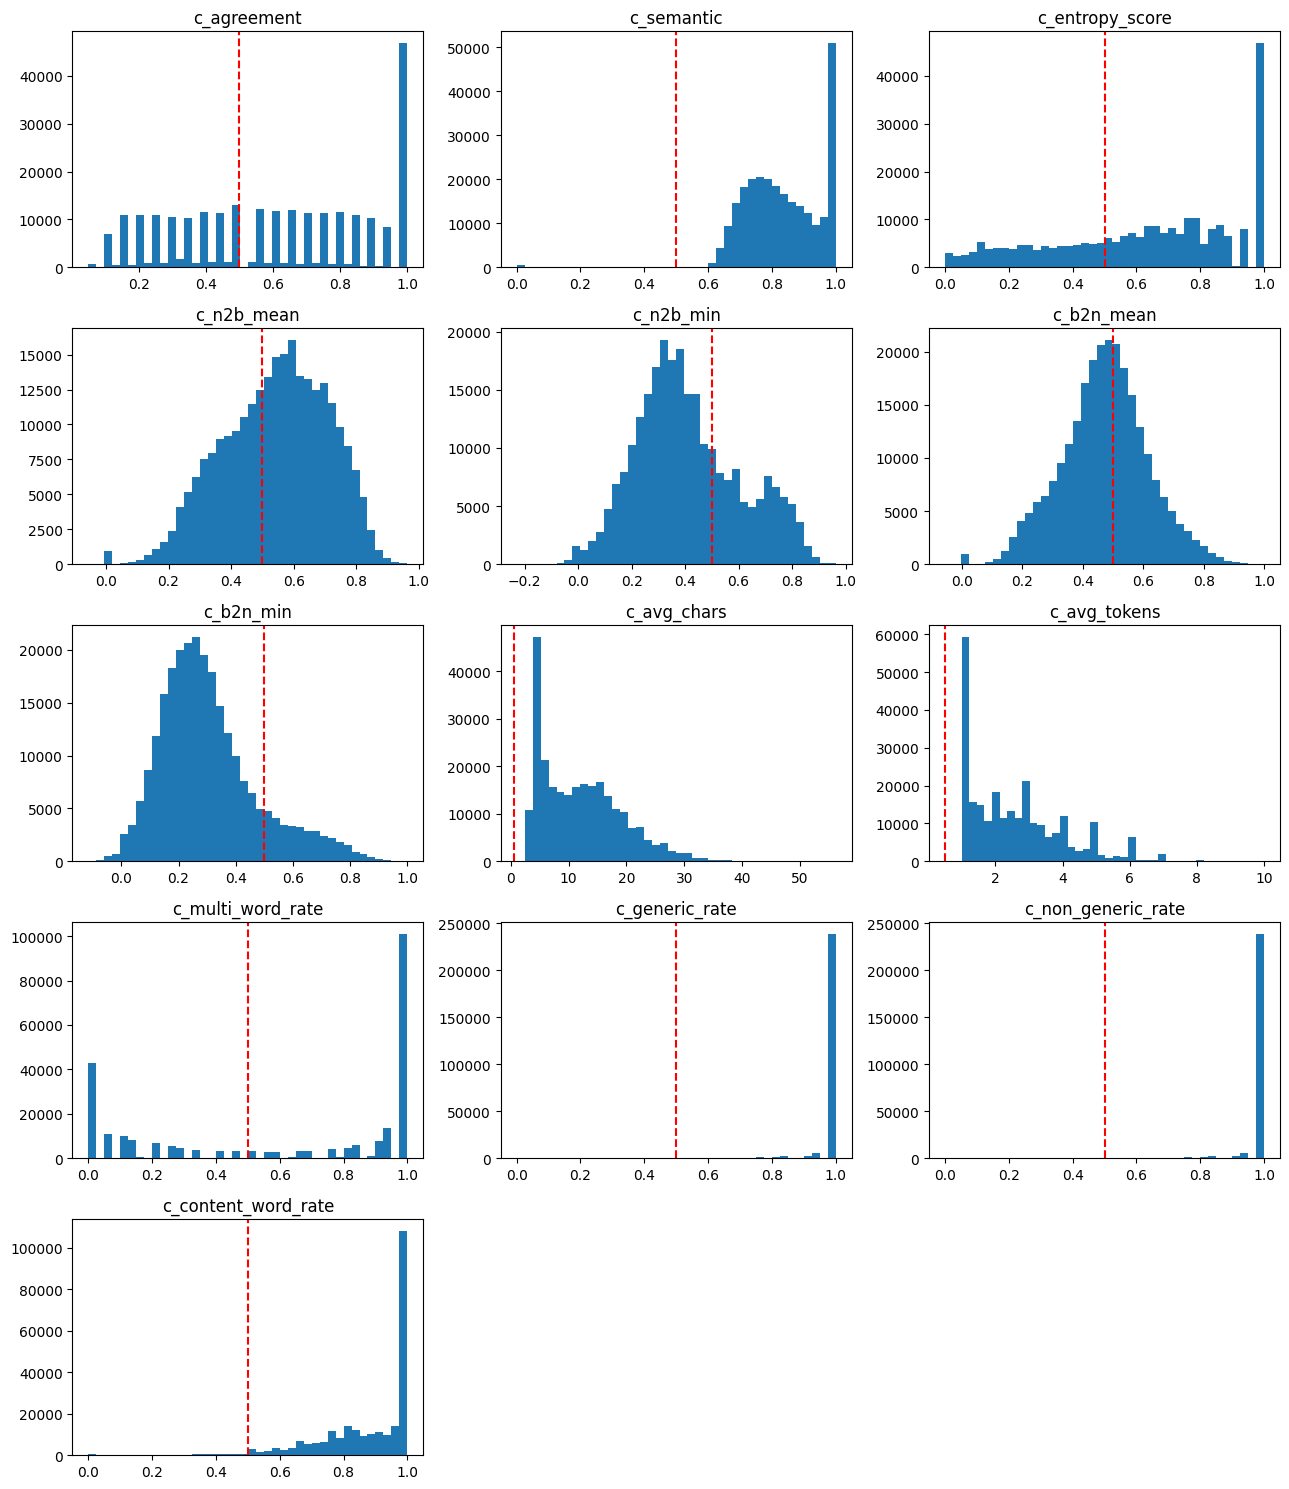

In [ ]:
absdf = pairs.loc[pairs.label==0, BEFORE_COLS].copy()
absdf.columns = [c.replace('before_','') for c in absdf.columns]
desc = absdf.describe().T[['mean','std','min','25%','50%','75%','max']]
desc['frac_at_0'] = (absdf < 0.02).mean().values
desc['frac_at_1'] = (absdf > 0.98).mean().values
print(desc.round(3))

ncol=3; nrow=int(np.ceil(len(absdf.columns)/ncol))
fig,ax=plt.subplots(nrow,ncol,figsize=(13,3*nrow)); ax=ax.ravel()
for i,c in enumerate(absdf.columns):
    ax[i].hist(absdf[c].dropna(),bins=40); ax[i].set_title(c); ax[i].axvline(0.5,ls='--',c='r')
for j in range(len(absdf.columns),len(ax)): ax[j].axis('off')
plt.tight_layout(); plt.show()

# **2.1b Features for the tree**


(a) every delta, standardized per project (pz_d_*): how unusual is this change, for this repo. (b) every before score (raw absolute baseline cohesion before_*).

In [ ]:
def add_project_z(df, feats, prefix='pz_', min_n=30, eps=1e-6):
    df = df.copy()
    ben = df[df.label==0]; gmu, gsd = ben[feats].mean(), ben[feats].std()
    cnt = ben.groupby('project')[feats[0]].count()
    pmu = ben.groupby('project')[feats].mean(); psd = ben.groupby('project')[feats].std()
    small = cnt[cnt < min_n].index
    pmu.loc[small] = gmu.values; psd.loc[small] = gsd.values
    psd = psd.where(psd > eps, gsd, axis=1)
    mu = pmu.reindex(df['project']).reset_index(drop=True)
    sd = psd.reindex(df['project']).reset_index(drop=True)
    base = df[feats].reset_index(drop=True)
    for f in feats: df[prefix+f] = ((base[f]-mu[f])/sd[f]).fillna(0).values
    return df

pairs = add_project_z(pairs, D_COLS)            # pz_d_*  (per-project standardized deltas)
PZ_DELTA = ['pz_'+f for f in D_COLS]
MODEL_FEATURES = PZ_DELTA + BEFORE_COLS         # (a) standardized deltas + (b) before scores
print('model features (%d):' % len(MODEL_FEATURES))
print('  deltas (pz):', len(PZ_DELTA), ' before:', len(BEFORE_COLS))

model features (26):
  deltas (pz): 13  before: 13


### 2.2 Feature correlation (settles collinearity)

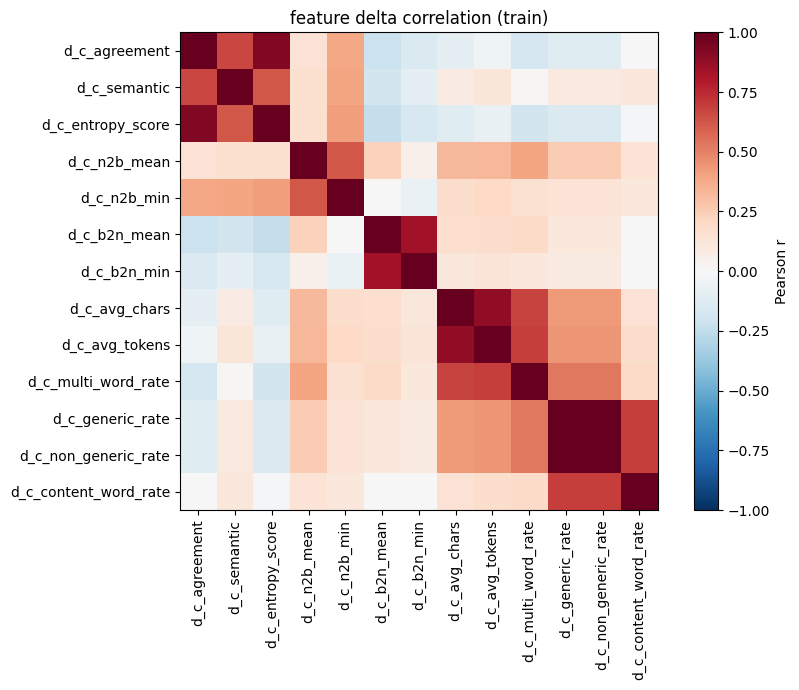

most correlated pairs:
  +1.00  d_c_generic_rate ~ d_c_non_generic_rate
  +0.92  d_c_agreement ~ d_c_entropy_score
  +0.89  d_c_avg_chars ~ d_c_avg_tokens
  +0.84  d_c_b2n_mean ~ d_c_b2n_min
  +0.69  d_c_generic_rate ~ d_c_content_word_rate
  +0.69  d_c_non_generic_rate ~ d_c_content_word_rate
  +0.69  d_c_avg_tokens ~ d_c_multi_word_rate
  +0.68  d_c_avg_chars ~ d_c_multi_word_rate


In [ ]:
cm = tr_df[D_COLS].corr()
plt.figure(figsize=(9,7)); plt.imshow(cm,vmin=-1,vmax=1,cmap='RdBu_r')
plt.xticks(range(len(D_COLS)),D_COLS,rotation=90); plt.yticks(range(len(D_COLS)),D_COLS)
plt.colorbar(label='Pearson r'); plt.title('feature delta correlation (train)'); plt.tight_layout(); plt.show()
pc=[(abs(cm.loc[a,b]),round(cm.loc[a,b],2),a,b) for i,a in enumerate(D_COLS) for b in D_COLS[i+1:]]
print('most correlated pairs:')
for _,r,a,b in sorted(pc,reverse=True)[:8]: print(f'  {r:+.2f}  {a} ~ {b}')

### 3. Build Detector — GroupKFold model selection

This section keeps the project-local baseline assumption:

> For each repository/project, the detector is allowed to use benign historical changes from that same repository to standardize cohesion deltas.

The split is still by project, so the classifier is evaluated on held-out projects. GroupKFold is used only inside the training projects to choose/tune the LightGBM configuration.

In [ ]:
from lightgbm import LGBMClassifier
from sklearn.model_selection import GroupKFold
from sklearn.metrics import average_precision_score, roc_auc_score

N_SIMULATIONS = 1000


def add_project_z_local(df, feats, prefix='pz_', min_n=30, eps=1e-6):
    """
    Project-local standardization.

    For each project:
        pz_d_metric = (d_metric - project_benign_mean) / project_benign_std

    The mean/std are calculated from benign rows of that same project.
    This matches the detector assumption: a repository's benign history is available
    for local calibration.
    """
    df = df.copy()
    ben = df[df.label == 0]

    if len(ben) == 0:
        # Defensive fallback; should not happen in the normal pipeline.
        for f in feats:
            df[prefix + f] = 0.0
        return df

    gmu = ben[feats].mean()
    gsd = ben[feats].std().replace(0, np.nan).fillna(1.0)

    cnt = ben.groupby('project')[feats[0]].count()
    pmu = ben.groupby('project')[feats].mean()
    psd = ben.groupby('project')[feats].std()

    small = cnt[cnt < min_n].index
    if len(small) > 0:
        pmu.loc[small] = gmu.values
        psd.loc[small] = gsd.values

    psd = psd.where(psd > eps, gsd, axis=1)

    mu = pmu.reindex(df['project']).reset_index(drop=True)
    sd = psd.reindex(df['project']).reset_index(drop=True)

    # If a project has no benign history in this subset, fall back to subset-global benign stats.
    mu = mu.fillna(gmu)
    sd = sd.fillna(gsd)

    base = df[feats].reset_index(drop=True)
    for f in feats:
        df[prefix + f] = ((base[f] - mu[f]) / sd[f]).fillna(0).values

    return df


def make_sample_weight(df):
    """
    Keeps the original weighting logic:
    1. class balancing
    2. per-version injection weighting
    """
    pos = df.label.mean()
    class_weight = np.where(df.label == 1, (1 - pos) / pos, 1.0)
    return class_weight * df.weight.values


def safe_weighted_metrics(df, scores):
    """Weighted AP and ROC AUC, with a safe ROC fallback for degenerate folds."""
    ap = average_precision_score(df.label.values, scores, sample_weight=df.weight.values)
    if df.label.nunique() < 2:
        roc = np.nan
    else:
        roc = roc_auc_score(df.label.values, scores, sample_weight=df.weight.values)
    return ap, roc


def run_group_cv_project_local(pairs, d_cols, before_cols, params, n_splits=5, seed=42):
    """
    GroupKFold CV on train projects only.

    - Folds are grouped by project.
    - No project appears in both fold-train and fold-validation.
    - Each fold side gets project-local standardization separately.
    - Validation projects may use their own benign history for local calibration.
    """
    train_raw = pairs[pairs.split == 'train'].copy()
    groups = train_raw['project']
    gkf = GroupKFold(n_splits=n_splits)

    fold_rows = []
    pz_cols = ['pz_' + c for c in d_cols]
    model_features = pz_cols + before_cols

    for fold, (tr_idx, va_idx) in enumerate(gkf.split(train_raw, train_raw.label, groups), start=1):
        fold_tr_raw = train_raw.iloc[tr_idx].copy()
        fold_va_raw = train_raw.iloc[va_idx].copy()

        # Project-local calibration is allowed independently for each project subset.
        fold_tr = add_project_z_local(fold_tr_raw, d_cols)
        fold_va = add_project_z_local(fold_va_raw, d_cols)

        clf = LGBMClassifier(**params, random_state=seed, verbose=-1)
        clf.fit(
            fold_tr[model_features].values,
            fold_tr.label.values,
            sample_weight=make_sample_weight(fold_tr)
        )

        va_scores = clf.predict_proba(fold_va[model_features].values)[:, 1]
        ap, roc = safe_weighted_metrics(fold_va, va_scores)

        fold_rows.append({
            'fold': fold,
            'AP': ap,
            'ROC_AUC': roc,
            'n_train_projects': fold_tr.project.nunique(),
            'n_val_projects': fold_va.project.nunique(),
            'n_train_rows': len(fold_tr),
            'n_val_rows': len(fold_va),
            'pos_rate_val': fold_va.label.mean(),
        })

        print(
            f"fold {fold}: AP={ap:.4f}, ROC_AUC={roc:.4f}, "
            f"train_projects={fold_tr.project.nunique()}, val_projects={fold_va.project.nunique()}"
        )

    return pd.DataFrame(fold_rows)


### 3.1 Compare LightGBM configurations with GroupKFold

Cross-validation is used only for model selection on the training projects. The held-out test projects remain untouched until the final model evaluation.

In [ ]:
param_grid = [
    # Baseline close to the original model
    {
        'n_estimators': 300,
        'learning_rate': 0.10,
        'max_depth': 5,
        'reg_lambda': 1.0,
    },
    # More conservative learning rate + sampling
    {
        'n_estimators': 300,
        'learning_rate': 0.05,
        'max_depth': 5,
        'num_leaves': 31,
        'reg_lambda': 1.0,
        'min_child_samples': 50,
        'subsample': 0.8,
        'colsample_bytree': 0.8,
    },
    # Slower model with stronger regularization
    {
        'n_estimators': 500,
        'learning_rate': 0.03,
        'max_depth': 4,
        'num_leaves': 31,
        'reg_lambda': 2.0,
        'min_child_samples': 100,
        'subsample': 0.8,
        'colsample_bytree': 0.8,
    },
    # Smaller tree model for overfit control
    {
        'n_estimators': 300,
        'learning_rate': 0.05,
        'max_depth': 3,
        'num_leaves': 15,
        'reg_lambda': 5.0,
        'min_child_samples': 100,
        'subsample': 0.8,
        'colsample_bytree': 0.8,
    },
]

all_cv = []

for config_id, params in enumerate(param_grid):
    print('\n' + '=' * 70)
    print(f'Running config {config_id}')
    print(params)
    print('=' * 70)

    cv_res = run_group_cv_project_local(
        pairs=pairs,
        d_cols=D_COLS,
        before_cols=BEFORE_COLS,
        params=params,
        n_splits=5,
        seed=SPLIT_SEED
    )

    cv_res['config_id'] = config_id
    all_cv.append(cv_res)

cv_results = pd.concat(all_cv, ignore_index=True)

cv_summary = (
    cv_results
    .groupby('config_id')[['AP', 'ROC_AUC']]
    .agg(['mean', 'std'])
    .sort_values(('AP', 'mean'), ascending=False)
)

display(cv_results)
display(cv_summary)

best_config_id = cv_summary.index[0]
best_params = param_grid[best_config_id]

print('Best config:', best_config_id)
print(best_params)



Running config 0
{'n_estimators': 300, 'learning_rate': 0.1, 'max_depth': 5, 'reg_lambda': 1.0}
fold 1: AP=0.8913, ROC_AUC=0.8788, train_projects=99, val_projects=1
fold 2: AP=0.9342, ROC_AUC=0.9255, train_projects=78, val_projects=22
fold 3: AP=0.9303, ROC_AUC=0.9094, train_projects=76, val_projects=24
fold 4: AP=0.9270, ROC_AUC=0.9105, train_projects=73, val_projects=27
fold 5: AP=0.9106, ROC_AUC=0.8999, train_projects=74, val_projects=26

Running config 1
{'n_estimators': 300, 'learning_rate': 0.05, 'max_depth': 5, 'num_leaves': 31, 'reg_lambda': 1.0, 'min_child_samples': 50, 'subsample': 0.8, 'colsample_bytree': 0.8}
fold 1: AP=0.8867, ROC_AUC=0.8743, train_projects=99, val_projects=1
fold 2: AP=0.9294, ROC_AUC=0.9205, train_projects=78, val_projects=22
fold 3: AP=0.9281, ROC_AUC=0.9072, train_projects=76, val_projects=24
fold 4: AP=0.9248, ROC_AUC=0.9077, train_projects=73, val_projects=27
fold 5: AP=0.9046, ROC_AUC=0.8942, train_projects=74, val_projects=26

Running config 2
{'n

,fold,AP,ROC_AUC,n_train_projects,n_val_projects,n_train_rows,n_val_rows,pos_rate_val,config_id
0,1,0.891285,0.878776,99,1,266995,191746,0.541545,0
1,2,0.934201,0.925475,78,22,391992,66749,0.660085,0
2,3,0.930343,0.909404,76,24,391992,66749,0.612414,0
3,4,0.927018,0.910462,73,27,391991,66750,0.627610,0
4,5,0.910550,0.899885,74,26,391994,66747,0.580685,0
5,1,0.886671,0.874335,99,1,266995,191746,0.541545,1
6,2,0.929377,0.920546,78,22,391992,66749,0.660085,1
7,3,0.928060,0.907165,76,24,391992,66749,0.612414,1
8,4,0.924764,0.907687,73,27,391991,66750,0.627610,1
9,5,0.904597,0.894160,74,26,391994,66747,0.580685,1


AP             ROC_AUC          
               mean       std      mean       std
config_id                                        
0          0.918679  0.017770  0.904800  0.017191
1          0.914694  0.018594  0.900778  0.017481
2          0.909855  0.019956  0.896435  0.018301
3          0.901766  0.022422  0.888447  0.021060

Best config: 0
{'n_estimators': 300, 'learning_rate': 0.1, 'max_depth': 5, 'reg_lambda': 1.0}


## Part 4 — Final model on train projects, evaluated on held-out test projects

The final model is trained once using all training projects and then evaluated once on the held-out test projects. Both train and test projects use project-local standardization, matching the benign-history assumption.

In [ ]:
def fit_final_model_project_local(pairs, d_cols, before_cols, params, seed=42):
    """
    Final train/test evaluation.

    Train/test split:
        already exists in pairs['split']

    Standardization:
        train projects use their own benign history
        test projects use their own benign history

    This matches the project-local detector assumption.
    """
    train_raw = pairs[pairs.split == 'train'].copy()
    test_raw = pairs[pairs.split == 'test'].copy()

    train_df = add_project_z_local(train_raw, d_cols)
    test_df = add_project_z_local(test_raw, d_cols)

    pz_cols = ['pz_' + c for c in d_cols]
    model_features = pz_cols + before_cols

    clf = LGBMClassifier(**params, random_state=seed, verbose=-1)
    clf.fit(
        train_df[model_features].values,
        train_df.label.values,
        sample_weight=make_sample_weight(train_df)
    )

    train_df['s'] = clf.predict_proba(train_df[model_features].values)[:, 1]
    test_df['s'] = clf.predict_proba(test_df[model_features].values)[:, 1]

    train_ap, train_roc = safe_weighted_metrics(train_df, train_df['s'].values)
    test_ap, test_roc = safe_weighted_metrics(test_df, test_df['s'].values)

    print(f'cross-project AP      train {train_ap:.3f}  test {test_ap:.3f}')
    print(f'cross-project ROC AUC train {train_roc:.3f}  test {test_roc:.3f}')

    return clf, model_features, train_df, test_df


clf_main, MODEL_FEATURES, tr_main, t_main = fit_final_model_project_local(
    pairs=pairs,
    d_cols=D_COLS,
    before_cols=BEFORE_COLS,
    params=best_params,
    seed=SPLIT_SEED
)

print('scored train:', tr_main.shape)
print('scored test: ', t_main.shape)


cross-project AP      train 0.945  test 0.916
cross-project ROC AUC train 0.933  test 0.906
scored train: (458741, 49)
scored test:  (185800, 49)


## Part 5 — Paper simulation

Use the scored held-out test set only. This reports P@100 and AP under class imbalance ratios 1:100, 1:1000, and 1:10000.

In [ ]:
def simulate(benign, groups, ratio, n_sim=N_SIMULATIONS, seed=42):
    """
    Paper-style simulation.

    For a given ratio 1:ratio:
        - use the benign test-score pool
        - sample malicious function/version groups
        - sample one injected candidate from each selected group
        - compute normalized P@100 and AP
    """
    rng = np.random.default_rng(seed)
    bs = np.asarray(benign)
    B = len(bs)

    if B == 0 or len(groups) == 0:
        return np.nan, np.nan, np.nan, 0

    n_mal = min(max(1, round(B / ratio)), len(groups))
    p100, aps = [], []

    for _ in range(n_sim):
        idx = rng.choice(len(groups), size=n_mal, replace=False)
        mal = np.array([groups[i][rng.integers(len(groups[i]))] for i in idx])

        s = np.concatenate([bs, mal])
        y = np.concatenate([np.zeros(B), np.ones(n_mal)])

        k = min(100, len(s))
        top = np.argpartition(-s, k - 1)[:k]

        # Normalized P@100: fraction of available malicious samples found in top 100.
        p100.append(y[top].sum() / min(100, n_mal))
        aps.append(average_precision_score(y, s))

    return np.mean(p100) * 100, np.std(p100) * 100, np.mean(aps), n_mal


def make_pools(t, mask=None):
    """
    Build benign score pool and grouped malicious score pool.

    Malicious rows are grouped by function/version so that many injection positions
    from the same function do not dominate the simulation.
    """
    if mask is not None:
        t = t[mask.loc[t.index]]

    benign = t.loc[t.label == 0, 's'].values

    groups = (
        t[t.label == 1]
        .groupby(['func_id', 'version_from'])['s']
        .apply(list)
        .values
    )

    return benign, groups


def run_ratio_table(t, title='ALL', ratios=RATIOS, seed=SPLIT_SEED):
    print(title)
    print(f"{'pool':9s} {'ratio':>7s} {'n_mal':>6s} {'P@100':>15s} {'AP':>7s}")

    benign, groups = make_pools(t)
    for r in ratios:
        p, sd, ap, nm = simulate(
            benign=benign,
            groups=groups,
            ratio=r,
            n_sim=N_SIMULATIONS,
            seed=seed
        )
        print(f"{'all':9s} 1:{r:<5d} {nm:6d} {p:7.2f}% +/-{sd:5.2f} {ap:7.3f}")


# Always use the scored held-out test set.
t = t_main.copy()
run_ratio_table(t, title='=== PAPER SIMULATION: ALL TEST PROJECTS ===')


=== PAPER SIMULATION: ALL TEST PROJECTS ===
pool        ratio  n_mal           P@100      AP
all       1:100      683   48.83% +/- 3.78   0.189
all       1:1000      68   10.09% +/- 3.49   0.040
all       1:10000      7   10.66% +/-11.93   0.018


## Part 6 — Cohesion-level analysis

Compute a `cohesion_index`, attach it to the scored test set, and then run:

1. all vs high-cohesion simulation
2. low/mid/high detectability trend

In [ ]:
# ---- Build candidate cohesion axes on the benign-version (before_*) scores ----

# Option 1: single metric. Simple, but potentially fragile.
OPT1 = 'before_c_n2b_mean'

# Option 2: composite index from better-distributed absolute cohesion metrics.
# Degenerate metrics are excluded.
COMP = [
    c for c in [
        'before_c_n2b_mean',
        'before_c_b2n_mean',
        'before_c_n2b_min',
        'before_c_b2n_min',
    ]
    if c in pairs.columns
]


def minmax_robust(x):
    lo, hi = x.quantile(0.01), x.quantile(0.99)
    return ((x - lo) / (hi - lo + 1e-9)).clip(0, 1)


if len(COMP) == 0:
    raise ValueError('No cohesion-index component columns were found. Check BEFORE_COLS / metric names.')

pairs['cohesion_index'] = np.mean(
    [minmax_robust(pairs[c].astype(float)) for c in COMP],
    axis=0
)
OPT2 = 'cohesion_index'

# Recommended: composite cohesion index.
GATE = OPT1
THRESH = pairs.loc[pairs.label == 0, GATE].median()

print('gate:', GATE)
print('components:', COMP)
print(pairs.loc[pairs.label == 0, GATE].describe().round(3))
print('threshold median:', round(THRESH, 3))

# Attach cohesion_index and selected gate to the already-scored train/test sets.
# t_main keeps the original row index from pairs, so this is a safe alignment.
tr_main = tr_main.copy()
t_main = t_main.copy()
tr_main['cohesion_index'] = pairs.loc[tr_main.index, 'cohesion_index'].values
t_main['cohesion_index'] = pairs.loc[t_main.index, 'cohesion_index'].values

if GATE != 'cohesion_index':
    tr_main[GATE] = pairs.loc[tr_main.index, GATE].values
    t_main[GATE] = pairs.loc[t_main.index, GATE].values


gate: before_c_n2b_mean
components: ['before_c_n2b_mean', 'before_c_b2n_mean', 'before_c_n2b_min', 'before_c_b2n_min']
count    257642.000
mean          0.542
std           0.167
min          -0.056
25%           0.424
50%           0.555
75%           0.670
max           0.963
Name: before_c_n2b_mean, dtype: float64
threshold median: 0.555


In [ ]:
from sklearn.metrics import roc_auc_score, roc_curve, auc
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


def safe_roc_auc(y_true, scores, sample_weight=None):
    """
    Computes ROC-AUC safely.
    Returns NaN if the subset contains only one class.
    """
    y_true = np.asarray(y_true)

    if len(np.unique(y_true)) < 2:
        return np.nan

    return roc_auc_score(
        y_true,
        scores,
        sample_weight=sample_weight
    )


def print_subset_roc_auc(t, name):
    """
    Prints ROC-AUC for a given dataframe subset.
    Uses the already-scored column t['s'].
    """
    roc = safe_roc_auc(
        y_true=t["label"].values,
        scores=t["s"].values,
        sample_weight=t["weight"].values if "weight" in t.columns else None
    )

    print(f"{name:12s} ROC-AUC: {roc:.4f}" if not np.isnan(roc) else f"{name:12s} ROC-AUC: NaN")


def plot_roc_curve_for_subset(t, name="test set"):
    """
    Plots ROC curve for a dataframe subset.
    Uses the already-scored column t['s'].
    """
    y_true = t["label"].values
    scores = t["s"].values
    sample_weight = t["weight"].values if "weight" in t.columns else None

    if len(np.unique(y_true)) < 2:
        print(f"Cannot plot ROC curve for {name}: only one class exists.")
        return

    fpr, tpr, thresholds = roc_curve(
        y_true,
        scores,
        sample_weight=sample_weight
    )

    roc_auc = auc(fpr, tpr)

    plt.figure(figsize=(6, 5))
    plt.plot(fpr, tpr, label=f"{name} ROC-AUC = {roc_auc:.3f}")
    plt.plot([0, 1], [0, 1], linestyle="--", label="random")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title(f"ROC Curve — {name}")
    plt.legend()
    plt.grid(True)
    plt.show()


def run_roc_auc_by_pool(t, gate, threshold):
    """
    ROC-AUC summary for:
        - all test rows
        - high-cohesion rows
        - low/mid/high cohesion strata
    """
    print("=== ROC-AUC BY POOL ===")

    print_subset_roc_auc(t, "all")

    high = t[t[gate] > threshold]
    print_subset_roc_auc(high, "high_coh")

    q = t[gate].quantile([0, .33, .66, 1.0]).values

    strata = [
        ("low", q[0], q[1]),
        ("mid", q[1], q[2]),
        ("high", q[2], q[3] + 1e-9),
    ]

    for sname, lo, hi in strata:
        sub = t[(t[gate] >= lo) & (t[gate] < hi)]
        print_subset_roc_auc(sub, sname)

=== ALL vs HIGH-COHESION ===
pool        ratio  n_mal           P@100      AP
all       1:100      683   48.83% +/- 3.78   0.189
all       1:1000      68   10.09% +/- 3.49   0.040
all       1:10000      7   10.66% +/-11.93   0.018
high_coh  1:100      350   39.94% +/- 4.34   0.202
high_coh  1:1000      35   15.99% +/- 6.10   0.044
high_coh  1:10000      4   16.62% +/-17.51   0.022

=== STRATIFIED low / mid / high (detectability trend) ===
quantile boundaries: [-0.006  0.491  0.608  0.963]
stratum    ratio  n_mal           P@100      AP
low      1:100      215   29.71% +/- 4.08   0.175
low      1:1000      22   15.99% +/- 7.81   0.050
mid      1:100      224   35.34% +/- 4.10   0.187
mid      1:1000      22   19.81% +/- 8.43   0.047
high     1:100      244   37.78% +/- 3.99   0.208
high     1:1000      24   19.81% +/- 8.06   0.048
=== ROC-AUC BY POOL ===
all          ROC-AUC: 0.9061
high_coh     ROC-AUC: 0.9142
low          ROC-AUC: 0.8961
mid          ROC-AUC: 0.9016
high         ROC-A

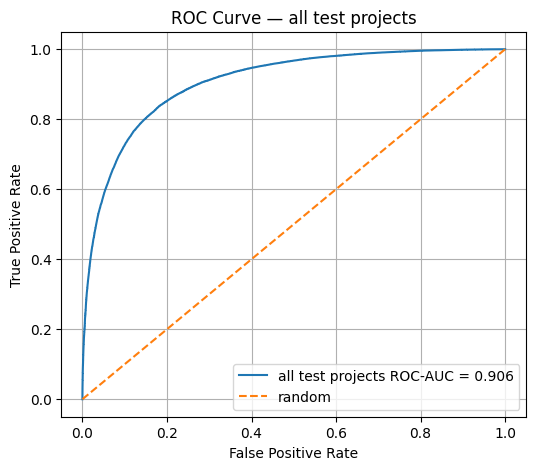

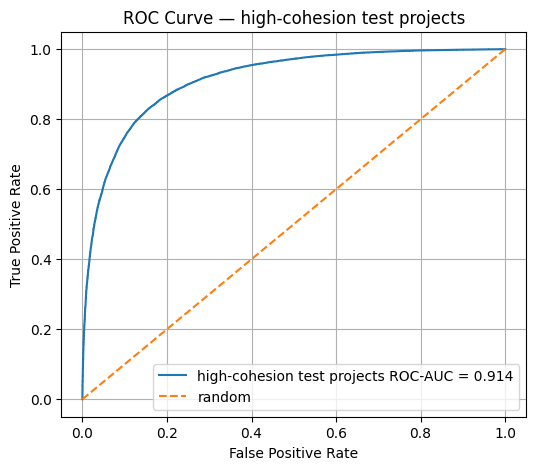

In [ ]:
def run_pool_comparison(t, gate, threshold, ratios=RATIOS, seed=SPLIT_SEED):
    print('=== ALL vs HIGH-COHESION ===')
    print(f"{'pool':9s} {'ratio':>7s} {'n_mal':>6s} {'P@100':>15s} {'AP':>7s}")

    for pool, mask in [
        ('all', None),
        ('high_coh', t[gate] > threshold),
    ]:
        sub = t[mask] if mask is not None else t
        benign, groups = make_pools(sub)

        for r in ratios:
            p, sd, ap, nm = simulate(
                benign=benign,
                groups=groups,
                ratio=r,
                n_sim=N_SIMULATIONS,
                seed=seed
            )
            print(f'{pool:9s} 1:{r:<5d} {nm:6d} {p:7.2f}% +/-{sd:5.2f} {ap:7.3f}')


def run_stratified_trend(t, gate, ratios=(100, 1000), seed=SPLIT_SEED):
    print('\n=== STRATIFIED low / mid / high (detectability trend) ===')

    q = t[gate].quantile([0, .33, .66, 1.0]).values
    print('quantile boundaries:', np.round(q, 3))
    print(f"{'stratum':8s} {'ratio':>7s} {'n_mal':>6s} {'P@100':>15s} {'AP':>7s}")

    strata = [
        ('low', q[0], q[1]),
        ('mid', q[1], q[2]),
        ('high', q[2], q[3] + 1e-9),
    ]

    for sname, lo, hi in strata:
        sub = t[(t[gate] >= lo) & (t[gate] < hi)]
        benign, groups = make_pools(sub)

        for r in ratios:
            p, sd, ap, nm = simulate(
                benign=benign,
                groups=groups,
                ratio=r,
                n_sim=N_SIMULATIONS,
                seed=seed
            )
            print(f'{sname:8s} 1:{r:<5d} {nm:6d} {p:7.2f}% +/-{sd:5.2f} {ap:7.3f}')


t = t_main.copy()
run_pool_comparison(t, gate=GATE, threshold=THRESH)
run_stratified_trend(t, gate=GATE)

run_roc_auc_by_pool(t, gate=GATE, threshold=THRESH)

plot_roc_curve_for_subset(t, name="all test projects")

high_t = t[t[GATE] > THRESH]
plot_roc_curve_for_subset(high_t, name="high-cohesion test projects")


In [ ]:
from sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix
import numpy as np
import pandas as pd


def evaluate_threshold_metrics(t, threshold=0.5, name="test"):
    """
    Compute precision, recall, F1, and confusion matrix
    using a fixed score threshold.
    """
    y_true = t["label"].values
    y_pred = (t["s"].values >= threshold).astype(int)

    precision = precision_score(y_true, y_pred, zero_division=0)
    recall = recall_score(y_true, y_pred, zero_division=0)
    f1 = f1_score(y_true, y_pred, zero_division=0)

    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()

    print(f"=== {name} threshold metrics @ {threshold:.3f} ===")
    print(f"Precision: {precision:.4f}")
    print(f"Recall:    {recall:.4f}")
    print(f"F1:        {f1:.4f}")
    print()
    print("Confusion matrix:")
    print(f"TN={tn:,}  FP={fp:,}")
    print(f"FN={fn:,}  TP={tp:,}")

    return {
        "name": name,
        "threshold": threshold,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "tn": tn,
        "fp": fp,
        "fn": fn,
        "tp": tp,
    }

In [ ]:
from sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix


def find_best_f1_threshold(t, thresholds=None):
    """
    Finds the threshold that maximizes F1 on a given scored dataframe.
    Use this on train or validation only, not on test.
    """
    if thresholds is None:
        thresholds = np.linspace(0.01, 0.99, 99)

    rows = []

    y_true = t["label"].values
    scores = t["s"].values

    for th in thresholds:
        y_pred = (scores >= th).astype(int)

        rows.append({
            "threshold": th,
            "precision": precision_score(y_true, y_pred, zero_division=0),
            "recall": recall_score(y_true, y_pred, zero_division=0),
            "f1": f1_score(y_true, y_pred, zero_division=0),
        })

    return pd.DataFrame(rows).sort_values("f1", ascending=False)


threshold_search = find_best_f1_threshold(tr_main)
display(threshold_search.head(10))

best_threshold = threshold_search.iloc[0]["threshold"]
print("Best train threshold:", best_threshold)

f1_result_test = evaluate_threshold_metrics(
    t_main,
    threshold=best_threshold,
    name="test projects using train-selected threshold"
)

,threshold,precision,recall,f1
34,0.35,0.859439,0.905771,0.881997
33,0.34,0.856118,0.909342,0.881928
35,0.36,0.862646,0.902086,0.881925
36,0.37,0.866004,0.898426,0.881917
32,0.33,0.852576,0.913035,0.881770
37,0.38,0.869329,0.894473,0.881722
38,0.39,0.872485,0.890587,0.881443
31,0.32,0.848817,0.916479,0.881351
39,0.40,0.875463,0.886816,0.881103
30,0.31,0.845239,0.920020,0.881046


Best train threshold: 0.35000000000000003
=== test projects using train-selected threshold threshold metrics @ 0.350 ===
Precision: 0.8572
Recall:    0.8788
F1:        0.8678

Confusion matrix:
TN=51,127  FP=17,203
FN=14,239  TP=103,231


## Part 7 — Explainability

Permutation importance is computed on the same scored held-out test set used for the final evaluation and simulations.

In [ ]:
# ============================================================
# Part 7 — Explainability: Metric Contribution Plot
# ============================================================

from sklearn.inspection import permutation_importance
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np


def grouped_metric_name(feature_name):
    """
    Maps model features back to their base cohesion metric.

    Examples:
        pz_d_agreement -> agreement
        before_agreement -> agreement
        pz_d_nbc_statement_level -> nbc_statement_level
    """
    name = feature_name

    if name.startswith("pz_d_"):
        name = name[len("pz_d_"):]
    elif name.startswith("d_"):
        name = name[len("d_"):]
    elif name.startswith("before_"):
        name = name[len("before_"):]
    elif name.startswith("b_"):
        name = name[len("b_"):]

    return name


def compute_grouped_permutation_importance(
    clf,
    test_df,
    model_features,
    scoring="average_precision",
    n_repeats=5,
    seed=42
):
    """
    Computes permutation importance on the scored test set,
    then aggregates feature importance by base metric.
    """
    X = test_df[model_features].values
    y = test_df["label"].values
    w = test_df["weight"].values if "weight" in test_df.columns else None

    result = permutation_importance(
        clf,
        X,
        y,
        scoring=scoring,
        n_repeats=n_repeats,
        random_state=seed,
        sample_weight=w,
        n_jobs=-1
    )

    feat_imp = pd.DataFrame({
        "feature": model_features,
        "importance_mean": result.importances_mean,
        "importance_std": result.importances_std,
    })

    feat_imp["metric"] = feat_imp["feature"].apply(grouped_metric_name)

    grouped = (
        feat_imp
        .groupby("metric", as_index=False)
        .agg(
            importance_mean=("importance_mean", "sum"),
            importance_std=("importance_std", "mean"),
            n_features=("feature", "count")
        )
        .sort_values("importance_mean", ascending=True)
    )

    return feat_imp, grouped

In [ ]:
feat_imp, grouped_imp = compute_grouped_permutation_importance(
    clf=clf_main,
    test_df=t_main,
    model_features=MODEL_FEATURES,
    scoring="average_precision",
    n_repeats=5,
    seed=SPLIT_SEED
)

display(feat_imp.sort_values("importance_mean", ascending=False))
display(grouped_imp.sort_values("importance_mean", ascending=False))

KeyboardInterrupt: 

In [ ]:
def plot_grouped_metric_contribution(grouped_imp, title=None):
    """
    Horizontal bar chart showing grouped permutation importance.

    Positive value:
        Permuting this metric hurts AP, meaning the metric contributes useful signal.

    Near zero or negative value:
        The metric contributes little or may add noise.
    """
    df = grouped_imp.copy().sort_values("importance_mean", ascending=True)

    if title is None:
        title = "Contribution of Cohesion Metrics to Malware Detection"

    plt.figure(figsize=(10, 6))

    values = df["importance_mean"].values
    labels = df["metric"].values

    plt.barh(labels, values)

    plt.axvline(0, linewidth=1)
    plt.xlabel("Permutation Importance: Drop in Average Precision")
    plt.ylabel("Metric Name")
    plt.title(title)
    plt.grid(axis="x", alpha=0.3)
    plt.tight_layout()
    plt.show()


plot_grouped_metric_contribution(grouped_imp)

In [ ]:
from sklearn.inspection import permutation_importance

te = t_main.copy()

imp = permutation_importance(
    clf_main,
    te[MODEL_FEATURES].values,
    te.label.values,
    scoring='average_precision',
    n_repeats=5,
    random_state=0,
    sample_weight=te.weight.values
)

imp_series = pd.Series(imp.importances_mean, index=MODEL_FEATURES).sort_values(ascending=False)
print('top-12 features by permutation importance:')
print(imp_series.head(12).round(4))

plt.figure(figsize=(9, 5))
imp_series.head(12).sort_values().plot(kind='barh')
plt.title('Top permutation importances on held-out test projects')
plt.xlabel('Mean AP decrease')
plt.tight_layout()
plt.show()

print('\nlength artifact check (benign vs injected should be ~equal):')
for col in ['before_c_avg_chars', 'before_c_avg_tokens']:
    if col in pairs.columns:
        print(
            f'  {col}: '
            f'benign {pairs[pairs.label == 0][col].mean():.3f}  '
            f'injected {pairs[pairs.label == 1][col].mean():.3f}'
        )



## Part 8 — Score JavaScript Function-Version Pairs

This section runs **after Part 7 — Explainability**.

It uses the trained C++ LightGBM model from this notebook to score JavaScript function-version pairs.

Input:
- `js_metrics.csv` — already contains the computed cohesion metrics for JS functions.

Output:
- `js_pairs_scored_by_cpp_model.csv`
- `js_top10_pairs_by_cpp_model.csv`
- `js_top100_pairs_by_cpp_model.csv`
- `js_version_scores_by_cpp_model.csv`


In [ ]:
# =========================
# Part 8 config: JS scoring
# =========================

JS_METRICS_CSV = DATA / "js_metrics.csv"

OUT_JS_PAIRS = DATA / "js_pairs_scored_by_cpp_model.csv"
OUT_JS_TOP10 = DATA / "js_top10_pairs_by_cpp_model.csv"
OUT_JS_TOP100 = DATA / "js_top100_pairs_by_cpp_model.csv"
OUT_JS_VERSION_SCORES = DATA / "js_version_scores_by_cpp_model.csv"

JS_SCORE_THRESHOLD = 0.80

print("JS metrics path:", JS_METRICS_CSV)

JS metrics path: /content/drive/MyDrive/Code Cohesion/new_method/data/js_metrics.csv


In [ ]:
# =========================
# Helpers: JS func_id parsing
# =========================

import re

try:
    from packaging.version import parse as parse_version
except Exception:
    parse_version = None


def parse_js_func_id(fid: str):
    """
    Expected:
      conventional-changelog@0.4.3/index.js:18:conventionalChangelog
      @scope/pkg@1.2.0/src/index.js:10:someFunc

    Returns:
      package, version_in_id, file_path, line, func_name
    """
    s = str(fid)
    try:
        left, func_name = s.rsplit(":", 1)
        left, line = left.rsplit(":", 1)
    except ValueError:
        return None, None, None, np.nan, None

    # package may contain @scope, so use the last @ before /file
    m = re.match(r"^(?P<package>.+)@(?P<version>[^/]+)/(?P<file_path>.+)$", left)
    if not m:
        return None, None, None, np.nan, func_name

    try:
        line = int(line)
    except Exception:
        line = np.nan

    return m.group("package"), m.group("version"), m.group("file_path"), line, func_name


def version_key(v):
    v = str(v)
    if parse_version is None:
        return v
    try:
        return parse_version(v)
    except Exception:
        return v

In [ ]:
# =========================
# Load JS metrics
# =========================

js = pd.read_csv(JS_METRICS_CSV)
js["version"] = js["version"].astype(str)

print("Loaded JS metrics:", js.shape)
print("JS columns:", list(js.columns))

missing_raw = [m for m in METRICS_RAW if m not in js.columns]
if missing_raw:
    raise ValueError(
        "JS metrics are missing columns required by the trained C++ model: "
        + str(missing_raw)
    )

display(js.head())

Loaded JS metrics: (87987, 17)
JS columns: ['func_id', 'version', 'injection_pos', 'agreement', 'semantic', 'entropy_score', 'and_penalty', 'avg_chars', 'avg_tokens', 'multi_word_rate', 'generic_rate', 'non_generic_rate', 'content_word_rate', 'n2b_mean', 'n2b_min', 'b2n_mean', 'b2n_min']


,func_id,version,injection_pos,agreement,semantic,entropy_score,and_penalty,avg_chars,avg_tokens,multi_word_rate,generic_rate,non_generic_rate,content_word_rate,n2b_mean,n2b_min,b2n_mean,b2n_min
0,conventional-changelog@0.4.3/index.js:18:conve...,0.4.3,NaN,1.0,1.000000,1.000000,0.0,18.0,2.0,1.0,0.0,1.0,1.000000,0.447036,0.447036,0.234819,-0.002677
1,conventional-changelog@0.5.0/index.js:19:conve...,0.5.0,NaN,1.0,1.000000,1.000000,0.0,18.0,2.0,1.0,0.0,1.0,1.000000,0.447036,0.447036,0.242113,-0.002677
2,conventional-changelog@0.5.1/index.js:19:conve...,0.5.1,NaN,1.0,1.000000,1.000000,0.0,18.0,2.0,1.0,0.0,1.0,1.000000,0.447036,0.447036,0.242113,-0.002677
3,conventional-changelog@0.5.3/index.js:19:conve...,0.5.3,NaN,1.0,1.000000,1.000000,0.0,18.0,2.0,1.0,0.0,1.0,1.000000,0.447036,0.447036,0.241881,-0.002677
4,conventional-changelog@1.0.0/index.js:4:conven...,1.0.0,NaN,0.7,0.827913,0.662933,0.0,20.9,2.6,0.8,0.0,1.0,0.961538,0.642586,0.455807,0.569634,0.373417


In [ ]:
# =========================
# Orient metrics and parse JS function IDs
# =========================

js, JS_COH = to_cohesion_oriented(js)

if JS_COH != COH:
    raise ValueError(
        f"JS oriented columns differ from training columns.\n"
        f"JS_COH={JS_COH}\nCOH={COH}"
    )

js = js.dropna(subset=COH).copy()

parsed = js["func_id"].apply(parse_js_func_id)
js[["package", "version_in_id", "file_path", "line", "func_name"]] = pd.DataFrame(
    parsed.tolist(), index=js.index
)

bad = js[["package", "file_path", "func_name"]].isna().any(axis=1).sum()
print("Bad/unparsed JS rows:", bad)

js["stable_func_id"] = (
    js["package"].astype(str)
    + PROJECT_SEP + js["file_path"].astype(str)
    + PROJECT_SEP + js["func_name"].astype(str)
)

js["project"] = js["package"].astype(str)
js["version_sort"] = js["version"].apply(version_key)

print("JS rows after metric cleanup:", js.shape)
print("Packages:", js["package"].nunique())
print("Stable functions:", js["stable_func_id"].nunique())

display(js[["func_id", "version", "package", "file_path", "line", "func_name", "stable_func_id"]].head())

Bad/unparsed JS rows: 0
JS rows after metric cleanup: (87987, 38)
Packages: 11
Stable functions: 23702


,func_id,version,package,file_path,line,func_name,stable_func_id
0,conventional-changelog@0.4.3/index.js:18:conve...,0.4.3,conventional-changelog,index.js,18,conventionalChangelog,conventional-changelog|index.js|conventionalCh...
1,conventional-changelog@0.5.0/index.js:19:conve...,0.5.0,conventional-changelog,index.js,19,conventionalChangelog,conventional-changelog|index.js|conventionalCh...
2,conventional-changelog@0.5.1/index.js:19:conve...,0.5.1,conventional-changelog,index.js,19,conventionalChangelog,conventional-changelog|index.js|conventionalCh...
3,conventional-changelog@0.5.3/index.js:19:conve...,0.5.3,conventional-changelog,index.js,19,conventionalChangelog,conventional-changelog|index.js|conventionalCh...
4,conventional-changelog@1.0.0/index.js:4:conven...,1.0.0,conventional-changelog,index.js,4,conventionalChangelog,conventional-changelog|index.js|conventionalCh...


In [ ]:
# =========================
# Build consecutive-version JS function pairs
# =========================

dup_count = js.duplicated(["stable_func_id", "version"]).sum()
print("Duplicate stable_func_id/version rows:", dup_count)

js_unique = (
    js.sort_values(["stable_func_id", "version_sort", "line"])
      .drop_duplicates(["stable_func_id", "version"], keep="first")
      .reset_index(drop=True)
)

cs_js = js_unique.sort_values(["stable_func_id", "version_sort"]).reset_index(drop=True)
g_js = cs_js.groupby("stable_func_id", sort=False)

after_js = g_js[COH].shift(-1)
vto_js = g_js["version"].shift(-1)
fid_to_js = g_js["func_id"].shift(-1)
line_to_js = g_js["line"].shift(-1)

valid_js = after_js[COH[0]].notna()

js_pairs = pd.DataFrame({
    "stable_func_id": cs_js["stable_func_id"],
    "func_id": cs_js["stable_func_id"],
    "package": cs_js["package"],
    "project": cs_js["project"],
    "file_path": cs_js["file_path"],
    "func_name": cs_js["func_name"],
    "version_from": cs_js["version"],
    "version_to": vto_js,
    "line_from": cs_js["line"],
    "line_to": line_to_js,
    "func_id_from": cs_js["func_id"],
    "func_id_to": fid_to_js,
})

for c in COH:
    js_pairs["d_" + c] = cs_js[c] - after_js[c]
    js_pairs["before_" + c] = cs_js[c]

js_pairs = js_pairs[valid_js].copy().reset_index(drop=True)
js_pairs["pair_id"] = (
    js_pairs["stable_func_id"]
    + PROJECT_SEP + js_pairs["version_from"].astype(str)
    + "->" + js_pairs["version_to"].astype(str)
)

# Unknown labels. Set label=0 only so add_project_z_local uses JS history as local calibration.
js_pairs["pair_type"] = "js_version_pair"
js_pairs["label"] = 0
js_pairs["weight"] = 1.0

JS_D_COLS = ["d_" + c for c in COH]
JS_BEFORE_COLS = ["before_" + c for c in COH]

if JS_D_COLS != D_COLS or JS_BEFORE_COLS != BEFORE_COLS:
    raise ValueError("JS feature column names do not match the trained model feature names.")

print("JS pairs:", js_pairs.shape)
print("Packages:", js_pairs["package"].nunique())
print("Stable functions with pairs:", js_pairs["stable_func_id"].nunique())

display(js_pairs.head())

Duplicate stable_func_id/version rows: 26341
JS pairs: (37944, 42)
Packages: 9
Stable functions with pairs: 6354


,stable_func_id,func_id,package,project,file_path,func_name,version_from,version_to,line_from,line_to,...,d_c_generic_rate,before_c_generic_rate,d_c_non_generic_rate,before_c_non_generic_rate,d_c_content_word_rate,before_c_content_word_rate,pair_id,pair_type,label,weight
0,conventional-changelog|dist/ConventionalChange...,conventional-changelog|dist/ConventionalChange...,conventional-changelog,conventional-changelog,dist/ConventionalChangelog.js,finalizeContext,7.0.1,7.0.2,67,67.0,...,0.05,1.00,0.05,1.00,0.092708,0.540984,conventional-changelog|dist/ConventionalChange...,js_version_pair,0,1.0
1,conventional-changelog|dist/ConventionalChange...,conventional-changelog|dist/ConventionalChange...,conventional-changelog,conventional-changelog,dist/ConventionalChangelog.js,finalizeContext,7.0.2,7.1.0,67,67.0,...,-0.05,0.95,-0.05,0.95,-0.014411,0.448276,conventional-changelog|dist/ConventionalChange...,js_version_pair,0,1.0
2,conventional-changelog|dist/ConventionalChange...,conventional-changelog|dist/ConventionalChange...,conventional-changelog,conventional-changelog,dist/ConventionalChangelog.js,finalizeContext,7.1.0,7.1.1,67,67.0,...,0.15,1.00,0.15,1.00,-0.037313,0.462687,conventional-changelog|dist/ConventionalChange...,js_version_pair,0,1.0
3,conventional-changelog|dist/ConventionalChange...,conventional-changelog|dist/ConventionalChange...,conventional-changelog,conventional-changelog,dist/ConventionalChangelog.js,finalizeContext,7.1.1,7.2.0,67,67.0,...,0.10,0.85,0.10,0.85,0.017857,0.500000,conventional-changelog|dist/ConventionalChange...,js_version_pair,0,1.0
4,conventional-changelog|dist/ConventionalChange...,conventional-changelog|dist/ConventionalChange...,conventional-changelog,conventional-changelog,dist/ConventionalChangelog.js,getCommits,7.0.1,7.1.1,171,171.0,...,-0.05,0.75,-0.05,0.75,0.065189,0.692308,conventional-changelog|dist/ConventionalChange...,js_version_pair,0,1.0


In [ ]:
# =========================
# Score JS pairs using the trained C++ LightGBM model
# =========================

js_pairs_z = add_project_z_local(js_pairs, D_COLS)

missing_model_features = [f for f in MODEL_FEATURES if f not in js_pairs_z.columns]
if missing_model_features:
    raise ValueError(f"Missing MODEL_FEATURES in JS pairs: {missing_model_features}")

js_pairs_z["s"] = clf_main.predict_proba(js_pairs_z[MODEL_FEATURES].values)[:, 1]
js_pairs_z["is_suspicious"] = js_pairs_z["s"] >= JS_SCORE_THRESHOLD

js_pairs_scored = js_pairs_z.sort_values("s", ascending=False).reset_index(drop=True)

print("Scored JS pairs:", js_pairs_scored.shape)
print("Suspicious pairs above threshold", JS_SCORE_THRESHOLD, ":", int(js_pairs_scored["is_suspicious"].sum()))

TOP_COLS_JS = [
    "s", "is_suspicious", "package", "version_from", "version_to",
    "file_path", "func_name", "line_from", "line_to",
    "func_id_from", "func_id_to"
] + D_COLS + BEFORE_COLS

print("Top 10 JS function-version pairs:")
display(js_pairs_scored[TOP_COLS_JS].head(10))

print("Top 100 JS function-version pairs:")
display(js_pairs_scored[TOP_COLS_JS].head(100))

Scored JS pairs: (37944, 57)
Suspicious pairs above threshold 0.8 : 1972
Top 10 JS function-version pairs:


,s,is_suspicious,package,version_from,version_to,file_path,func_name,line_from,line_to,func_id_from,...,before_c_n2b_mean,before_c_n2b_min,before_c_b2n_mean,before_c_b2n_min,before_c_avg_chars,before_c_avg_tokens,before_c_multi_word_rate,before_c_generic_rate,before_c_non_generic_rate,before_c_content_word_rate
0,0.997472,True,pm-controls,0.0.53,0.0.54,build/client/source/vendor.js,simplifyInContext,62927,62644.0,pm-controls@0.0.53/build/client/source/vendor....,...,0.835265,0.835265,0.353270,0.095778,10.00,1.00,0.00,1.00,1.00,1.000000
1,0.997450,True,pm-controls,0.0.36,0.0.65,build/client/source/vendor.js,daysInMonth,16067,16224.0,pm-controls@0.0.36/build/client/source/vendor....,...,0.608475,0.519533,0.647242,0.647242,17.65,4.20,0.95,1.00,1.00,0.809524
2,0.997346,True,pm-controls,0.0.26,0.0.33,lib/app/controls/components/grid/grid-settings...,GridSettingsColumnPanelComponent,16,16.0,pm-controls@0.0.26/lib/app/controls/components...,...,0.639975,0.405074,0.738431,0.732595,20.55,3.25,0.85,0.85,0.85,0.938462
3,0.996808,True,pm-controls,0.0.36,0.0.65,build/client/source/vendor.js,sequenceEqual,113934,96230.0,pm-controls@0.0.36/build/client/source/vendor....,...,0.479463,0.029730,0.686808,0.686808,16.70,2.45,0.80,0.90,0.90,0.959184
4,0.996485,True,react,15.4.1,15.4.2,dist/react-with-addons.min.js,c,12,12.0,react@15.4.1/dist/react-with-addons.min.js:12:c,...,0.514795,0.233926,0.561074,0.497176,16.45,1.90,0.80,1.00,1.00,1.000000
5,0.996474,True,pm-controls,0.0.54,0.0.65,build/client/source/app.js,poke,37621,45416.0,pm-controls@0.0.54/build/client/source/app.js:...,...,0.647071,0.474478,0.702526,0.682177,12.15,2.40,0.80,1.00,1.00,0.875000
6,0.996338,True,pm-controls,0.0.36,0.0.53,build/client/source/vendor.js,size,75333,82886.0,pm-controls@0.0.36/build/client/source/vendor....,...,0.574592,0.385334,0.756290,0.696970,12.30,2.25,0.90,0.90,0.90,0.666667
7,0.995599,True,pm-controls,0.0.46,0.0.47,build/client/source/app.js,cluster,43954,43954.0,pm-controls@0.0.46/build/client/source/app.js:...,...,0.741227,0.527574,0.426529,0.271448,7.55,1.10,0.05,0.95,0.95,0.954545
8,0.995548,True,pm-controls,0.0.53,0.0.54,build/client/source/vendor.js,last,80653,75901.0,pm-controls@0.0.53/build/client/source/vendor....,...,0.372162,0.185856,0.518962,0.465811,13.35,3.05,0.85,1.00,1.00,0.622951
9,0.995332,True,react,16.0.0-alpha.13,16.2.0,umd/react.production.min.js,t,4,12.0,react@16.0.0-alpha.13/umd/react.production.min...,...,0.444829,0.358164,0.620481,0.620481,18.30,2.35,0.95,1.00,1.00,1.000000


Top 100 JS function-version pairs:


,s,is_suspicious,package,version_from,version_to,file_path,func_name,line_from,line_to,func_id_from,...,before_c_n2b_mean,before_c_n2b_min,before_c_b2n_mean,before_c_b2n_min,before_c_avg_chars,before_c_avg_tokens,before_c_multi_word_rate,before_c_generic_rate,before_c_non_generic_rate,before_c_content_word_rate
0,0.997472,True,pm-controls,0.0.53,0.0.54,build/client/source/vendor.js,simplifyInContext,62927,62644.0,pm-controls@0.0.53/build/client/source/vendor....,...,0.835265,0.835265,0.353270,0.095778,10.00,1.00,0.00,1.00,1.00,1.000000
1,0.997450,True,pm-controls,0.0.36,0.0.65,build/client/source/vendor.js,daysInMonth,16067,16224.0,pm-controls@0.0.36/build/client/source/vendor....,...,0.608475,0.519533,0.647242,0.647242,17.65,4.20,0.95,1.00,1.00,0.809524
2,0.997346,True,pm-controls,0.0.26,0.0.33,lib/app/controls/components/grid/grid-settings...,GridSettingsColumnPanelComponent,16,16.0,pm-controls@0.0.26/lib/app/controls/components...,...,0.639975,0.405074,0.738431,0.732595,20.55,3.25,0.85,0.85,0.85,0.938462
3,0.996808,True,pm-controls,0.0.36,0.0.65,build/client/source/vendor.js,sequenceEqual,113934,96230.0,pm-controls@0.0.36/build/client/source/vendor....,...,0.479463,0.029730,0.686808,0.686808,16.70,2.45,0.80,0.90,0.90,0.959184
4,0.996485,True,react,15.4.1,15.4.2,dist/react-with-addons.min.js,c,12,12.0,react@15.4.1/dist/react-with-addons.min.js:12:c,...,0.514795,0.233926,0.561074,0.497176,16.45,1.90,0.80,1.00,1.00,1.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,0.977385,True,pm-controls,0.0.36,0.0.65,build/client/source/vendor.js,mapTo,112205,94762.0,pm-controls@0.0.36/build/client/source/vendor....,...,0.572185,0.059106,0.769336,0.769336,10.00,2.50,0.90,0.95,0.95,0.960000
96,0.977381,True,pm-controls,0.0.61,0.0.62,build/client/source/polyfills.js,get,2277,2277.0,pm-controls@0.0.61/build/client/source/polyfil...,...,0.446065,0.272072,0.512941,0.484848,17.80,3.45,1.00,1.00,1.00,0.797101
97,0.977329,True,pm-controls,0.0.12,0.0.17,lib/app/controls/components/context-menu/conte...,ContextMenuComponent,14,14.0,pm-controls@0.0.12/lib/app/controls/components...,...,0.816188,0.441263,0.882218,0.882218,6.10,1.70,0.70,0.75,0.75,0.441176
98,0.977091,True,pm-controls,0.0.57,0.0.58,build/client/source/vendor.js,create,20945,20945.0,pm-controls@0.0.57/build/client/source/vendor....,...,0.597501,0.456728,0.488691,0.289806,18.45,2.45,0.80,0.95,0.95,0.734694


Error: Runtime no longer has a reference to this dataframe, please re-run this cell and try again.


In [ ]:
# =========================
# Aggregate function-pair scores to version-update scores
# =========================

js_version_scores = (
    js_pairs_scored
    .groupby(["package", "version_from", "version_to"], as_index=False)
    .agg(
        version_score=("s", "max"),
        top3_mean=("s", lambda x: x.nlargest(min(3, len(x))).mean()),
        n_pairs=("s", "size"),
        n_suspicious=("is_suspicious", "sum"),
    )
    .sort_values("version_score", ascending=False)
    .reset_index(drop=True)
)

js_version_scores["version_flagged"] = js_version_scores["version_score"] >= JS_SCORE_THRESHOLD

print("Top JS version updates by max function-pair score:")
display(js_version_scores.head(50))

Top JS version updates by max function-pair score:


,package,version_from,version_to,version_score,top3_mean,n_pairs,n_suspicious,version_flagged
0,pm-controls,0.0.53,0.0.54,0.997472,0.993714,508,40,True
1,pm-controls,0.0.36,0.0.65,0.997450,0.995886,166,42,True
2,pm-controls,0.0.26,0.0.33,0.997346,0.359255,5,1,True
3,react,15.4.1,15.4.2,0.996485,0.986205,30,4,True
4,pm-controls,0.0.54,0.0.65,0.996474,0.979404,233,28,True
5,pm-controls,0.0.36,0.0.53,0.996338,0.993893,346,42,True
6,pm-controls,0.0.46,0.0.47,0.995599,0.968114,214,10,True
7,react,16.0.0-alpha.13,16.2.0,0.995332,0.687933,4,2,True
8,react,0.13.0-beta.2,15.2.0-rc.1,0.994956,0.964161,6,3,True
9,pm-controls,0.0.66,0.0.67,0.994642,0.979287,264,10,True


In [ ]:
# =========================
# Save JS scoring outputs
# =========================

js_pairs_scored.to_csv(OUT_JS_PAIRS, index=False)
js_pairs_scored.head(10)[TOP_COLS_JS].to_csv(OUT_JS_TOP10, index=False)
js_pairs_scored.head(100)[TOP_COLS_JS].to_csv(OUT_JS_TOP100, index=False)
js_version_scores.to_csv(OUT_JS_VERSION_SCORES, index=False)

print("Saved:")
print(" -", OUT_JS_PAIRS)
print(" -", OUT_JS_TOP10)
print(" -", OUT_JS_TOP100)
print(" -", OUT_JS_VERSION_SCORES)

Saved:
 - /content/drive/MyDrive/Code Cohesion/new_method/data/js_pairs_scored_by_cpp_model.csv
 - /content/drive/MyDrive/Code Cohesion/new_method/data/js_top10_pairs_by_cpp_model.csv
 - /content/drive/MyDrive/Code Cohesion/new_method/data/js_top100_pairs_by_cpp_model.csv
 - /content/drive/MyDrive/Code Cohesion/new_method/data/js_version_scores_by_cpp_model.csv


## Part 9 — Identify Known Malicious JS Functions and Calculate P@100

This section labels the known malicious package versions/files from the Differential CodeQL dataset, then reports:

1. The suspiciousness score of the known malicious functions.
2. Their rank inside the same npm package.
3. Their global rank across all JS function-version pairs.
4. Function-level **P@100** for the JS ranking.

In [ ]:

# =========================
# Load existing JS scoring CSVs to avoid recalculating
# =========================

# These should already exist from Part 8.
OUT_JS_PAIRS = DATA / "js_pairs_scored_by_cpp_model.csv"
OUT_JS_VERSION_SCORES = DATA / "js_version_scores_by_cpp_model.csv"

if not OUT_JS_PAIRS.exists():
    raise FileNotFoundError(f"Missing scored JS pairs file: {OUT_JS_PAIRS}")

if not OUT_JS_VERSION_SCORES.exists():
    raise FileNotFoundError(f"Missing JS version scores file: {OUT_JS_VERSION_SCORES}")

js_pairs_scored = pd.read_csv(OUT_JS_PAIRS)
js_version_scores = pd.read_csv(OUT_JS_VERSION_SCORES)

# Ensure expected types
for c in ["package", "version_from", "version_to", "file_path", "func_name"]:
    if c in js_pairs_scored.columns:
        js_pairs_scored[c] = js_pairs_scored[c].astype(str)

for c in ["package", "version_from", "version_to"]:
    if c in js_version_scores.columns:
        js_version_scores[c] = js_version_scores[c].astype(str)

# Recreate TOP_COLS_JS if the kernel was restarted.
D_COLS = [c for c in js_pairs_scored.columns if c.startswith("d_")]
BEFORE_COLS = [c for c in js_pairs_scored.columns if c.startswith("before_")]

TOP_COLS_JS = [
    "s", "is_suspicious", "package", "version_from", "version_to",
    "file_path", "func_name", "line_from", "line_to",
    "func_id_from", "func_id_to"
] + D_COLS + BEFORE_COLS

TOP_COLS_JS = [c for c in TOP_COLS_JS if c in js_pairs_scored.columns]

print("Loaded existing JS pairs:", js_pairs_scored.shape)
print("Loaded existing JS version scores:", js_version_scores.shape)

display(js_pairs_scored.head())
display(js_version_scores.head())


Loaded existing JS pairs: (37944, 57)
Loaded existing JS version scores: (2129, 8)


,stable_func_id,func_id,package,project,file_path,func_name,version_from,version_to,line_from,line_to,...,pz_d_c_b2n_mean,pz_d_c_b2n_min,pz_d_c_avg_chars,pz_d_c_avg_tokens,pz_d_c_multi_word_rate,pz_d_c_generic_rate,pz_d_c_non_generic_rate,pz_d_c_content_word_rate,s,is_suspicious
0,pm-controls|build/client/source/vendor.js|simp...,pm-controls|build/client/source/vendor.js|simp...,pm-controls,pm-controls,build/client/source/vendor.js,simplifyInContext,0.0.53,0.0.54,62927,62644.0,...,1.009097,0.194122,2.334590,0.021075,0.019172,0.001797,0.001797,0.001141,0.997472,True
1,pm-controls|build/client/source/vendor.js|days...,pm-controls|build/client/source/vendor.js|days...,pm-controls,pm-controls,build/client/source/vendor.js,daysInMonth,0.0.36,0.0.65,16067,16224.0,...,1.151268,5.101482,0.243896,2.223417,0.714293,1.329184,1.329184,0.516462,0.997450,True
2,pm-controls|lib/app/controls/components/grid/g...,pm-controls|lib/app/controls/components/grid/g...,pm-controls,pm-controls,lib/app/controls/components/grid/grid-settings...,GridSettingsColumnPanelComponent,0.0.26,0.0.33,16,16.0,...,3.423250,5.093960,1.872692,1.397539,0.366732,0.444260,0.444260,3.056583,0.997346,True
3,pm-controls|build/client/source/vendor.js|sequ...,pm-controls|build/client/source/vendor.js|sequ...,pm-controls,pm-controls,build/client/source/vendor.js,sequenceEqual,0.0.36,0.0.65,113934,96230.0,...,3.009973,2.917434,2.261659,1.672831,1.756974,1.771647,1.771647,1.396389,0.996808,True
4,react|dist/react-with-addons.min.js|c,react|dist/react-with-addons.min.js|c,react,react,dist/react-with-addons.min.js,c,15.4.1,15.4.2,12,12.0,...,0.688503,1.897409,2.056647,-0.007094,1.153550,1.915890,1.915890,3.241457,0.996485,True


,package,version_from,version_to,version_score,top3_mean,n_pairs,n_suspicious,version_flagged
0,pm-controls,0.0.53,0.0.54,0.997472,0.993714,508,40,True
1,pm-controls,0.0.36,0.0.65,0.997450,0.995886,166,42,True
2,pm-controls,0.0.26,0.0.33,0.997346,0.359255,5,1,True
3,react,15.4.1,15.4.2,0.996485,0.986205,30,4,True
4,pm-controls,0.0.54,0.0.65,0.996474,0.979404,233,28,True


In [ ]:
# =========================
# Known malicious versions and infected files
# =========================

# Known malicious versions from the DiffStaticAnalyzer / Backstabbers evaluation.
MALICIOUS_VERSIONS = {
    ("eslint-scope", "3.7.2"),
    ("conventional-changelog", "1.2.0"),
    ("flatmap-stream", "0.1.1"),
    ("getcookies", "1.12.3"),
    ("kraken-api", "0.1.8"),
    ("pm-controls", "1.1.8"),
    ("vue-backbone", "0.1.2"),
    ("ua-parser-js", "0.7.29"),

    # rpc-websocket malicious range
    ("rpc-websocket", "0.7.7"),
    ("rpc-websocket", "0.7.8"),
    ("rpc-websocket", "0.7.9"),
    ("rpc-websocket", "0.7.10"),
    ("rpc-websocket", "0.7.11"),
}

# Known files that contain the malicious behavior.
# Note: package.json-only attacks are not directly covered by our function-level method.
MALICIOUS_FILES = {
    ("eslint-scope", "3.7.2"): ["lib/build.js"],
    ("conventional-changelog", "1.2.0"): ["index.js"],
    ("flatmap-stream", "0.1.1"): ["index.min.js"],
    ("getcookies", "1.12.3"): ["harness.js"],
    ("kraken-api", "0.1.8"): ["lint.js"],
    ("pm-controls", "1.1.8"): ["dist/main.bundle.js"],
    ("vue-backbone", "0.1.2"): ["dist/vue-backbone.min.js"],
    ("ua-parser-js", "0.7.29"): ["preinstall.js"],

    ("rpc-websocket", "0.7.7"): ["lint.js"],
    ("rpc-websocket", "0.7.8"): ["lint.js"],
    ("rpc-websocket", "0.7.9"): ["lint.js"],
    ("rpc-websocket", "0.7.10"): ["lint.js"],
    ("rpc-websocket", "0.7.11"): ["lint.js"],
}


def is_known_malicious_version(row):
    return (str(row["package"]), str(row["version_to"])) in MALICIOUS_VERSIONS


def is_known_malicious_file(row):
    key = (str(row["package"]), str(row["version_to"]))
    files = MALICIOUS_FILES.get(key, [])
    file_path = str(row["file_path"])
    return any(f in file_path for f in files)


# Add labels to function-pair ranking.
js_pairs_scored = js_pairs_scored.copy()
js_pairs_scored["is_malicious_version"] = js_pairs_scored.apply(is_known_malicious_version, axis=1)
js_pairs_scored["is_malicious_file"] = js_pairs_scored.apply(is_known_malicious_file, axis=1)

# Define "malicious function" for this function-level evaluation:
# the pair targets a known malicious version AND the function comes from the known infected file.
js_pairs_scored["is_malicious_function_candidate"] = (
    js_pairs_scored["is_malicious_version"] & js_pairs_scored["is_malicious_file"]
)

print("Known malicious version pairs found:", int(js_pairs_scored["is_malicious_version"].sum()))
print("Known malicious file/function-pair candidates found:", int(js_pairs_scored["is_malicious_function_candidate"].sum()))

Known malicious version pairs found: 264
Known malicious file/function-pair candidates found: 74


In [ ]:
# =========================
# Global rank and rank within each package/project
# =========================

js_pairs_scored = js_pairs_scored.sort_values("s", ascending=False).reset_index(drop=True)

# Rank 1 = highest suspiciousness score.
js_pairs_scored["total_rank"] = np.arange(1, len(js_pairs_scored) + 1)

js_pairs_scored["project_rank"] = (
    js_pairs_scored
    .groupby("package")["s"]
    .rank(method="first", ascending=False)
    .astype(int)
)

# Helpful denominators for interpretation.
js_pairs_scored["project_n_pairs"] = js_pairs_scored.groupby("package")["s"].transform("size")

malware_function_rows = (
    js_pairs_scored[js_pairs_scored["is_malicious_function_candidate"]]
    .sort_values(["package", "version_to", "project_rank"])
    .copy()
)

MALWARE_VIEW_COLS = [
    "s",
    "is_suspicious",
    "total_rank",
    "project_rank",
    "project_n_pairs",
    "package",
    "version_from",
    "version_to",
    "file_path",
    "func_name",
    "line_from",
    "line_to",
    "func_id_from",
    "func_id_to",
]

print("Known malicious function/file candidates with model scores and ranks:")
display(malware_function_rows[MALWARE_VIEW_COLS])

Known malicious function/file candidates with model scores and ranks:


,s,is_suspicious,total_rank,project_rank,project_n_pairs,package,version_from,version_to,file_path,func_name,line_from,line_to,func_id_from,func_id_to
4360,0.617815,False,4361,19,74,conventional-changelog,1.1.19,1.2.0,index.js,conventionalChangelog,6,8.0,conventional-changelog@1.1.19/index.js:6:conve...,conventional-changelog@1.2.0/index.js:8:conven...
136,0.972462,True,137,67,10587,pm-controls,1.1.7,1.1.8,dist/main.bundle.js,View_TreeComponent_0,16648,16648.0,pm-controls@1.1.7/dist/main.bundle.js:16648:Vi...,pm-controls@1.1.8/dist/main.bundle.js:16648:Vi...
516,0.931196,True,517,180,10587,pm-controls,1.1.7,1.1.8,dist/main.bundle.js,View_TooltipComponent_0,16539,16539.0,pm-controls@1.1.7/dist/main.bundle.js:16539:Vi...,pm-controls@1.1.8/dist/main.bundle.js:16539:Vi...
575,0.924188,True,576,198,10587,pm-controls,1.1.7,1.1.8,dist/main.bundle.js,ComboBoxComponent,1415,1415.0,pm-controls@1.1.7/dist/main.bundle.js:1415:Com...,pm-controls@1.1.8/dist/main.bundle.js:1415:Com...
587,0.923347,True,588,201,10587,pm-controls,1.1.7,1.1.8,dist/main.bundle.js,SidebarComponent,15766,15766.0,pm-controls@1.1.7/dist/main.bundle.js:15766:Si...,pm-controls@1.1.8/dist/main.bundle.js:15766:Si...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
37554,0.003456,False,37555,10433,10587,pm-controls,1.1.7,1.1.8,dist/main.bundle.js,View_BreadcrumbComponent_Host_0,2340,2340.0,pm-controls@1.1.7/dist/main.bundle.js:2340:Vie...,pm-controls@1.1.8/dist/main.bundle.js:2340:Vie...
37726,0.002687,False,37727,10501,10587,pm-controls,1.1.7,1.1.8,dist/main.bundle.js,View_TooltipComponent_Host_0,16540,16540.0,pm-controls@1.1.7/dist/main.bundle.js:16540:Vi...,pm-controls@1.1.8/dist/main.bundle.js:16540:Vi...
28939,0.031442,False,28940,107,122,rpc-websocket,0.7.9,0.7.10,lint.js,c,4,4.0,rpc-websocket@0.7.9/lint.js:4:c,rpc-websocket@0.7.10/lint.js:4:c
4301,0.622614,False,4302,21,122,rpc-websocket,0.7.8,0.7.9,lint.js,c,4,4.0,rpc-websocket@0.7.8/lint.js:4:c,rpc-websocket@0.7.9/lint.js:4:c


In [ ]:
# =========================
# Version-level malware ranking
# =========================

js_version_scores = js_version_scores.copy()
js_version_scores["is_malicious_version"] = js_version_scores.apply(
    lambda r: (str(r["package"]), str(r["version_to"])) in MALICIOUS_VERSIONS,
    axis=1
)

js_version_scores = js_version_scores.sort_values("version_score", ascending=False).reset_index(drop=True)
js_version_scores["total_version_rank"] = np.arange(1, len(js_version_scores) + 1)
js_version_scores["project_version_rank"] = (
    js_version_scores
    .groupby("package")["version_score"]
    .rank(method="first", ascending=False)
    .astype(int)
)

print("Known malicious versions with max function-pair score and ranks:")
display(
    js_version_scores[js_version_scores["is_malicious_version"]]
    .sort_values(["package", "version_to"])
)

Known malicious versions with max function-pair score and ranks:


,package,version_from,version_to,version_score,top3_mean,n_pairs,n_suspicious,version_flagged,is_malicious_version,total_version_rank,project_version_rank
917,conventional-changelog,1.1.19,1.2.0,0.617815,0.617815,1,0,False,True,918,19
1023,eslint-scope,3.7.1,3.7.2,0.538579,0.228633,6,0,False,True,1024,38
90,pm-controls,1.1.7,1.1.8,0.972462,0.963206,224,10,True,True,91,33
299,rpc-websocket,0.7.9,0.7.10,0.927754,0.535638,7,1,True,True,300,4
863,rpc-websocket,0.7.10,0.7.11,0.648222,0.577109,6,0,False,True,864,14
658,rpc-websocket,0.7.6,0.7.7,0.772882,0.622991,6,0,False,True,659,10
986,rpc-websocket,0.7.7,0.7.8,0.569966,0.393465,6,0,False,True,987,17
243,rpc-websocket,0.7.8,0.7.9,0.939529,0.787787,7,2,True,True,244,3
1870,vue-backbone,0.1.1,0.1.2,0.062909,0.062909,1,0,False,True,1871,4


In [ ]:
# =========================
# Function-level P@100 for JS
# =========================

K = 100
top_k = js_pairs_scored.head(K).copy()

n_mal_in_top_k = int(top_k["is_malicious_function_candidate"].sum())
denom = min(K, len(js_pairs_scored))
p_at_100 = n_mal_in_top_k / denom if denom else np.nan

print(f"JS Function-level P@100 = {p_at_100:.4f} ({n_mal_in_top_k}/{denom})")

print("Malicious function/file candidates that appear in the top 100:")
display(top_k[top_k["is_malicious_function_candidate"]][MALWARE_VIEW_COLS])

# Also show top 100 with labels for quick inspection.
display(top_k[
    ["s", "total_rank", "project_rank", "package", "version_from", "version_to",
     "file_path", "func_name", "is_malicious_function_candidate", "is_malicious_version", "is_malicious_file"]
])

JS Function-level P@100 = 0.0000 (0/100)
Malicious function/file candidates that appear in the top 100:


,s,is_suspicious,total_rank,project_rank,project_n_pairs,package,version_from,version_to,file_path,func_name,line_from,line_to,func_id_from,func_id_to


,s,total_rank,project_rank,package,version_from,version_to,file_path,func_name,is_malicious_function_candidate,is_malicious_version,is_malicious_file
0,0.997472,1,1,pm-controls,0.0.53,0.0.54,build/client/source/vendor.js,simplifyInContext,False,False,False
1,0.997450,2,2,pm-controls,0.0.36,0.0.65,build/client/source/vendor.js,daysInMonth,False,False,False
2,0.997346,3,3,pm-controls,0.0.26,0.0.33,lib/app/controls/components/grid/grid-settings...,GridSettingsColumnPanelComponent,False,False,False
3,0.996808,4,4,pm-controls,0.0.36,0.0.65,build/client/source/vendor.js,sequenceEqual,False,False,False
4,0.996485,5,1,react,15.4.1,15.4.2,dist/react-with-addons.min.js,c,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...
95,0.977385,96,49,pm-controls,0.0.36,0.0.65,build/client/source/vendor.js,mapTo,False,False,False
96,0.977381,97,50,pm-controls,0.0.61,0.0.62,build/client/source/polyfills.js,get,False,False,False
97,0.977329,98,51,pm-controls,0.0.12,0.0.17,lib/app/controls/components/context-menu/conte...,ContextMenuComponent,False,False,False
98,0.977091,99,52,pm-controls,0.0.57,0.0.58,build/client/source/vendor.js,create,False,False,False


In [ ]:
# =========================
# Save malware rank outputs
# =========================

OUT_JS_MALWARE_FUNCTION_RANKS = DATA / "js_malware_function_ranks.csv"
OUT_JS_PAIRS_WITH_LABELS = DATA / "js_pairs_scored_with_malware_labels.csv"
OUT_JS_VERSION_RANKS_WITH_LABELS = DATA / "js_version_scores_with_malware_labels.csv"

malware_function_rows.to_csv(OUT_JS_MALWARE_FUNCTION_RANKS, index=False)
js_pairs_scored.to_csv(OUT_JS_PAIRS_WITH_LABELS, index=False)
js_version_scores.to_csv(OUT_JS_VERSION_RANKS_WITH_LABELS, index=False)

print("Saved:")
print(" -", OUT_JS_MALWARE_FUNCTION_RANKS)
print(" -", OUT_JS_PAIRS_WITH_LABELS)
print(" -", OUT_JS_VERSION_RANKS_WITH_LABELS)

Saved:
 - /content/drive/MyDrive/Code Cohesion/new_method/data/js_malware_function_ranks.csv
 - /content/drive/MyDrive/Code Cohesion/new_method/data/js_pairs_scored_with_malware_labels.csv
 - /content/drive/MyDrive/Code Cohesion/new_method/data/js_version_scores_with_malware_labels.csv


In [ ]:
# How far are the known malicious function/file candidates from the top?
mal = js_pairs_scored[js_pairs_scored["is_malicious_function_candidate"]].copy()

print("Number of malicious function/file candidates:", len(mal))

display(
    mal[[
        "s", "total_rank", "project_rank", "project_n_pairs",
        "package", "version_from", "version_to",
        "file_path", "func_name",
        "func_id_from", "func_id_to"
    ]]
    .sort_values("total_rank")
    .head(50)
)

print("Best malicious rank:")
display(
    mal.sort_values("total_rank")
    .groupby(["package", "version_to"])
    .head(1)[[
        "package", "version_to", "file_path", "func_name",
        "s", "total_rank", "project_rank", "project_n_pairs"
    ]]
    .sort_values("total_rank")
)

Number of malicious function/file candidates: 74


,s,total_rank,project_rank,project_n_pairs,package,version_from,version_to,file_path,func_name,func_id_from,func_id_to
136,0.972462,137,67,10587,pm-controls,1.1.7,1.1.8,dist/main.bundle.js,View_TreeComponent_0,pm-controls@1.1.7/dist/main.bundle.js:16648:Vi...,pm-controls@1.1.8/dist/main.bundle.js:16648:Vi...
516,0.931196,517,180,10587,pm-controls,1.1.7,1.1.8,dist/main.bundle.js,View_TooltipComponent_0,pm-controls@1.1.7/dist/main.bundle.js:16539:Vi...,pm-controls@1.1.8/dist/main.bundle.js:16539:Vi...
575,0.924188,576,198,10587,pm-controls,1.1.7,1.1.8,dist/main.bundle.js,ComboBoxComponent,pm-controls@1.1.7/dist/main.bundle.js:1415:Com...,pm-controls@1.1.8/dist/main.bundle.js:1415:Com...
587,0.923347,588,201,10587,pm-controls,1.1.7,1.1.8,dist/main.bundle.js,SidebarComponent,pm-controls@1.1.7/dist/main.bundle.js:15766:Si...,pm-controls@1.1.8/dist/main.bundle.js:15766:Si...
1347,0.852737,1348,362,10587,pm-controls,1.1.7,1.1.8,dist/main.bundle.js,TextBoxComponent,pm-controls@1.1.7/dist/main.bundle.js:2269:Tex...,pm-controls@1.1.8/dist/main.bundle.js:2269:Tex...
2032,0.793274,2033,523,10587,pm-controls,1.1.7,1.1.8,dist/main.bundle.js,TabsComponent,pm-controls@1.1.7/dist/main.bundle.js:16232:Ta...,pm-controls@1.1.8/dist/main.bundle.js:16232:Ta...
2112,0.787154,2113,546,10587,pm-controls,1.1.7,1.1.8,dist/main.bundle.js,View_TooltipComponent_1,pm-controls@1.1.7/dist/main.bundle.js:16538:Vi...,pm-controls@1.1.8/dist/main.bundle.js:16538:Vi...
3480,0.678272,3481,881,10587,pm-controls,1.1.7,1.1.8,dist/main.bundle.js,View_TreeComponent_1,pm-controls@1.1.7/dist/main.bundle.js:16647:Vi...,pm-controls@1.1.8/dist/main.bundle.js:16647:Vi...
3703,0.664114,3704,932,10587,pm-controls,1.1.7,1.1.8,dist/main.bundle.js,View_ListBoxComponent_Host_0,pm-controls@1.1.7/dist/main.bundle.js:1820:Vie...,pm-controls@1.1.8/dist/main.bundle.js:1820:Vie...
4301,0.622614,4302,21,122,rpc-websocket,0.7.8,0.7.9,lint.js,c,rpc-websocket@0.7.8/lint.js:4:c,rpc-websocket@0.7.9/lint.js:4:c


Best malicious rank:


,package,version_to,file_path,func_name,s,total_rank,project_rank,project_n_pairs
136,pm-controls,1.1.8,dist/main.bundle.js,View_TreeComponent_0,0.972462,137,67,10587
4301,rpc-websocket,0.7.9,lint.js,c,0.622614,4302,21,122
4360,conventional-changelog,1.2.0,index.js,conventionalChangelog,0.617815,4361,19,74
23720,vue-backbone,0.1.2,dist/vue-backbone.min.js,o,0.062909,23721,13,17
28939,rpc-websocket,0.7.10,lint.js,c,0.031442,28940,107,122


In [ ]:
# For each malicious package/version, where is the best malicious function inside its own package?
best_per_malware_version = (
    mal.sort_values("project_rank")
    .groupby(["package", "version_to"])
    .head(1)
)

display(
    best_per_malware_version[[
        "package", "version_to", "file_path", "func_name",
        "s", "project_rank", "project_n_pairs", "total_rank"
    ]]
    .sort_values("project_rank")
)

,package,version_to,file_path,func_name,s,project_rank,project_n_pairs,total_rank
23720,vue-backbone,0.1.2,dist/vue-backbone.min.js,o,0.062909,13,17,23721
4360,conventional-changelog,1.2.0,index.js,conventionalChangelog,0.617815,19,74,4361
4301,rpc-websocket,0.7.9,lint.js,c,0.622614,21,122,4302
136,pm-controls,1.1.8,dist/main.bundle.js,View_TreeComponent_0,0.972462,67,10587,137
28939,rpc-websocket,0.7.10,lint.js,c,0.031442,107,122,28940
